# Uji Validitas Butir dan Reliabilitas Instrumen
**Mata kuliah:** Probabilitas dan Statistika  |  **Data:** Kuesioner AI, Kebiasaan Digital, dan Prokrastinasi Akademik (kelas 3 TI A)  
**Alat:** Python (pandas, numpy, scipy, matplotlib)

## Langkah 1 - Impor pustaka

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    from google.colab import files      # hanya ada di Google Colab
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

## Langkah 2 - Unggah berkas data
Unggah file Excel hasil unduhan spreadsheet (hanya berisi data kuesioner). Jika dijalankan di komputer sendiri, letakkan file di folder yang sama dengan notebook.

In [3]:
if DI_COLAB:
    up = files.upload()
    nama_file = list(up.keys())[0]
else:
    nama_file = "Blank_Quiz__Responses_.xlsx"
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


## Langkah 3 - Membaca data, memilih kelas 3 TI A, dan memisahkan butir
Kolom 1-4 = demografi (Timestamp, Score, Kelas, Jenis Kelamin), kolom 5-6 = jumlah platform AI (bukan skala Likert), sehingga butir pernyataan dimulai dari kolom ke-7. Kolom *Durasi gadget* bukan butir Likert (tidak ada tanda `[ ]`), jadi dikeluarkan.

In [4]:
KELAS = "3 TI A"
JUMLAH_KOLOM_DEMOGRAFI = 6          # 4 demografi + 2 kolom jumlah platform AI

df_semua = pd.read_excel(nama_file)
df = df_semua[df_semua["Kelas"] == KELAS].reset_index(drop=True)

butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
butir = butir[[k for k in butir.columns if "[" in k]]   # buang kolom non-Likert (Durasi gadget)

print("Total baris di berkas :", len(df_semua))
print("Responden kelas", KELAS, ":", len(df))
print("Jumlah butir          :", butir.shape[1])
print("Data kosong           :", int(butir.isna().sum().sum()))

Total baris di berkas : 181
Responden kelas 3 TI A : 39
Jumlah butir          : 29
Data kosong           : 0


## Langkah 4 - Mengubah jawaban Likert menjadi angka

In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))   # harus 0
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_4285/2263531978.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
1,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
2,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
3,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
4,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


## Langkah 5 - Mengelompokkan butir per dimensi
Nama dimensi diambil dari teks sebelum tanda `[`, lalu dirapikan dengan `.strip()` karena ada spasi di awal/akhir pada beberapa judul kolom. Nama tampilan dan kode butir dibuat agar tabel laporan rapi (typo pada judul kolom asli diperbaiki hanya pada nama tampilan).

In [6]:
NAMA_TAMPIL = {
    "Penggunaan AI pada tugas atau projek kuliah"                  : ("PA", "Penggunaan AI pada Tugas atau Projek Kuliah"),
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah" : ("AP", "Aspek Psikologis Penggunaan AI pada Tugas atau Projek Kuliah"),
    "Kebiasaan penggunaan teknologi digital"                       : ("KT", "Kebiasaan Penggunaan Teknologi Digital"),
    "Prokrastinasi akademik."                                      : ("PR", "Prokrastinasi Akademik"),
    "Rsspon emosional"                                             : ("RE", "Respon Emosional"),
}

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{NAMA_TAMPIL[nama][1]}: {len(daftar)} butir")

Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir
Aspek Psikologis Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir
Kebiasaan Penggunaan Teknologi Digital: 6 butir
Prokrastinasi Akademik: 4 butir
Respon Emosional: 5 butir


## Langkah 6 - Uji validitas (korelasi Pearson butir-total)
$r_{tabel} = t / \sqrt{df + t^2}$ dengan $df = n-2$ dan $t$ kritis dua sisi $\alpha = 0{,}05$. Butir valid jika $r_{hitung} > r_{tabel}$.

In [7]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (alpha=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    kode, _ = NAMA_TAMPIL[nama]
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": NAMA_TAMPIL[nama][1],
            "Kode Butir": f"{kode}{i}",
            "Rata-rata": round(x[kolom].mean(), 2),
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (alpha=0,05; df=37) = 0.316


,Dimensi,Kode Butir,Rata-rata,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada Tugas atau Projek Kuliah,PA1,4.03,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada Tugas atau Projek Kuliah,PA2,4.49,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada Tugas atau Projek Kuliah,PA3,4.26,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada Tugas atau Projek Kuliah,PA4,2.95,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada Tugas atau Projek Kuliah,PA5,2.97,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada Tugas atau Projek Kuliah,PA6,4.18,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,4.41,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP1,3.49,0.538,0.228,0.0004,Valid
8,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP2,3.03,0.645,0.377,0.0000,Valid
9,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP3,2.49,0.495,0.213,0.0014,Valid


## Langkah 7 - Uji reliabilitas (Cronbach's alpha dan alpha jika butir dihapus)

In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas, alpha_dihapus = [], []
alpha_dim = {}
for nama, daftar in dimensi.items():
    kode, nama_tampil = NAMA_TAMPIL[nama]
    x = num[daftar]
    a = cronbach_alpha(x)
    alpha_dim[nama_tampil] = a
    hasil_reliabilitas.append({"Dimensi": nama_tampil, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({"Dimensi": nama_tampil, "Kode Butir": f"{kode}{i}",
                                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis Penggunaan AI pada Tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,6,0.478,Tidak reliabel
3,Prokrastinasi Akademik,4,0.863,Baik
4,Respon Emosional,5,0.489,Tidak reliabel


,Dimensi,Kode Butir,Alpha jika dihapus
0,Penggunaan AI pada Tugas atau Projek Kuliah,PA1,0.275
1,Penggunaan AI pada Tugas atau Projek Kuliah,PA2,0.362
2,Penggunaan AI pada Tugas atau Projek Kuliah,PA3,0.193
3,Penggunaan AI pada Tugas atau Projek Kuliah,PA4,0.171
4,Penggunaan AI pada Tugas atau Projek Kuliah,PA5,0.367
5,Penggunaan AI pada Tugas atau Projek Kuliah,PA6,0.348
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,0.513
7,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP1,0.299
8,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP2,0.200
9,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP3,0.312


## Langkah 8 - Keputusan tiap butir
Mengikuti pedoman pengambilan keputusan pada modul (r hitung vs r tabel dan alpha jika butir dihapus vs alpha dimensi).

In [9]:
def keputusan(valid, alpha_hapus, alpha_dimensi):
    naik = alpha_hapus > alpha_dimensi          # True = membuang butir menaikkan alpha
    if valid and not naik:  return "Pertahankan"
    if valid and naik:      return "Valid, tinjau isi butir"
    if not valid and naik:  return "Buang/revisi, uji ulang"
    return "Tinjau ulang sebelum dibuang"

gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Kode Butir"], how="left")
gabung["Keputusan"] = [
    keputusan(r["Keterangan"] == "Valid", r["Alpha jika dihapus"], alpha_dim[r["Dimensi"]])
    for _, r in gabung.iterrows()
]
print("Butir valid (r hitung > r tabel)  :", (gabung["Keterangan"] == "Valid").sum(), "dari", len(gabung))
print("Butir corrected r >= 0,30         :", (gabung["Corrected r"] >= 0.30).sum(), "dari", len(gabung))
gabung

Butir valid (r hitung > r tabel)  : 24 dari 29
Butir corrected r >= 0,30         : 13 dari 29


,Dimensi,Kode Butir,Rata-rata,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus,Keputusan
0,Penggunaan AI pada Tugas atau Projek Kuliah,PA1,4.03,0.525,0.277,0.0006,Valid,0.275,Pertahankan
1,Penggunaan AI pada Tugas atau Projek Kuliah,PA2,4.49,0.269,0.105,0.0972,Tidak valid,0.362,Tinjau ulang sebelum dibuang
2,Penggunaan AI pada Tugas atau Projek Kuliah,PA3,4.26,0.643,0.379,0.0000,Valid,0.193,Pertahankan
3,Penggunaan AI pada Tugas atau Projek Kuliah,PA4,2.95,0.669,0.397,0.0000,Valid,0.171,Pertahankan
4,Penggunaan AI pada Tugas atau Projek Kuliah,PA5,2.97,0.515,0.126,0.0008,Valid,0.367,Pertahankan
5,Penggunaan AI pada Tugas atau Projek Kuliah,PA6,4.18,0.455,0.139,0.0036,Valid,0.348,Pertahankan
6,Penggunaan AI pada Tugas atau Projek Kuliah,PA7,4.41,0.016,-0.247,0.9237,Tidak valid,0.513,"Buang/revisi, uji ulang"
7,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP1,3.49,0.538,0.228,0.0004,Valid,0.299,Pertahankan
8,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP2,3.03,0.645,0.377,0.0000,Valid,0.200,Pertahankan
9,Aspek Psikologis Penggunaan AI pada Tugas atau...,AP3,2.49,0.495,0.213,0.0014,Valid,0.312,Pertahankan


## Langkah 9 - Statistik deskriptif per dimensi
Skor dimensi = rata-rata skor butir tiap responden (skala 1-5). Skewness dan kurtosis memakai estimasi tak bias (excess kurtosis; distribusi normal = 0).

In [10]:
deskriptif = []
for nama, daftar in dimensi.items():
    skor = num[daftar].mean(axis=1)
    deskriptif.append({
        "Dimensi": NAMA_TAMPIL[nama][1],
        "n": len(skor),
        "Mean": round(skor.mean(), 3),
        "Std. Deviasi": round(skor.std(ddof=1), 3),
        "Min": round(skor.min(), 2),
        "Maks": round(skor.max(), 2),
        "Skewness": round(stats.skew(skor, bias=False), 3),
        "Kurtosis": round(stats.kurtosis(skor, bias=False), 3),
    })
tabel_deskriptif = pd.DataFrame(deskriptif)
tabel_deskriptif

,Dimensi,n,Mean,Std. Deviasi,Min,Maks,Skewness,Kurtosis
0,Penggunaan AI pada Tugas atau Projek Kuliah,39,3.897,0.431,2.71,4.86,-0.425,1.612
1,Aspek Psikologis Penggunaan AI pada Tugas atau...,39,3.132,0.534,2.14,4.29,0.248,-0.752
2,Kebiasaan Penggunaan Teknologi Digital,39,2.782,0.620,1.33,4.00,-0.255,-0.212
3,Prokrastinasi Akademik,39,2.763,1.016,1.00,4.75,0.236,-0.553
4,Respon Emosional,39,3.877,0.664,1.40,5.00,-1.524,3.948


## Langkah 10 - Grafik komposisi jawaban per dimensi

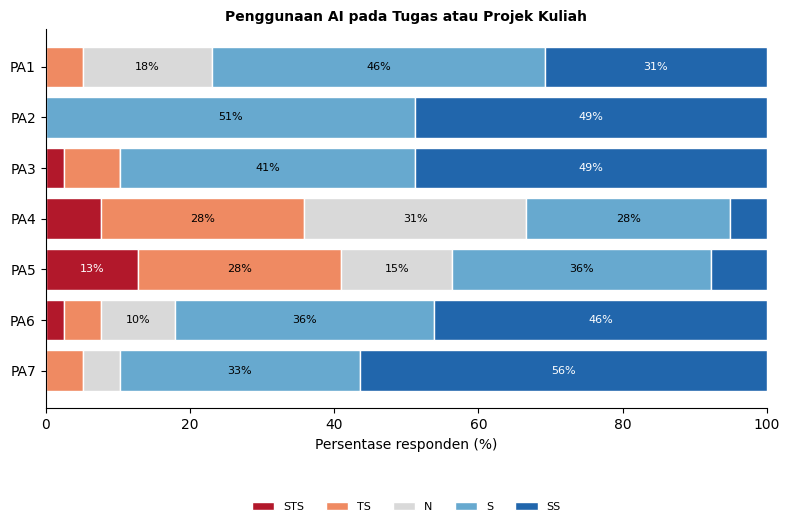

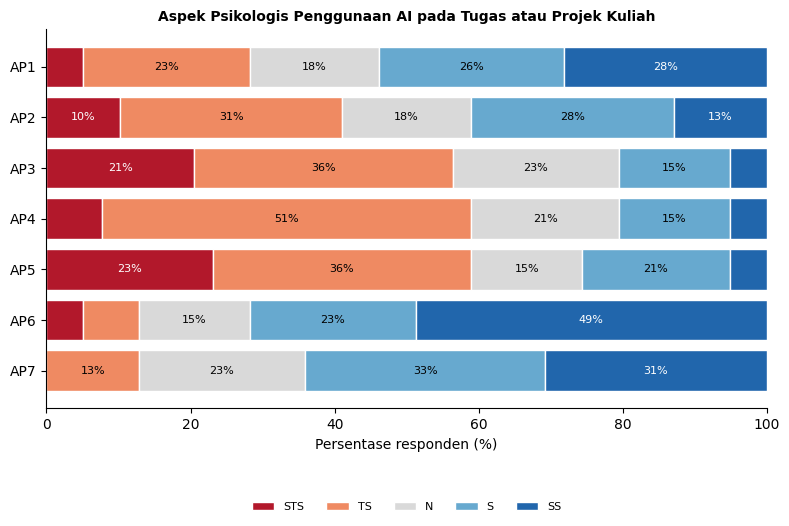

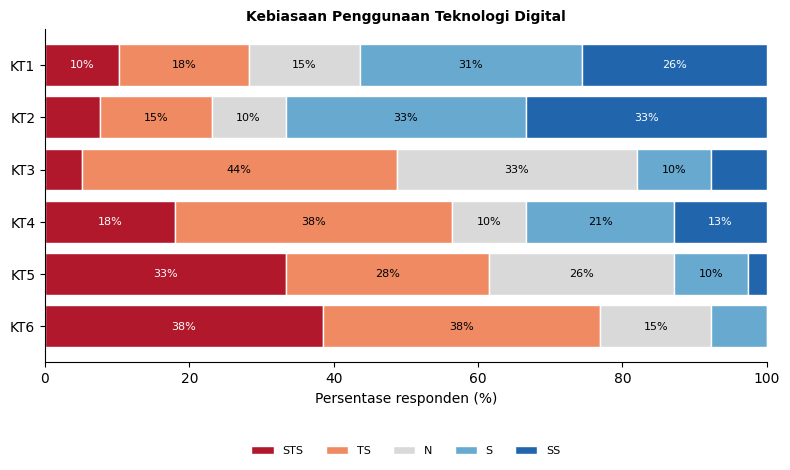

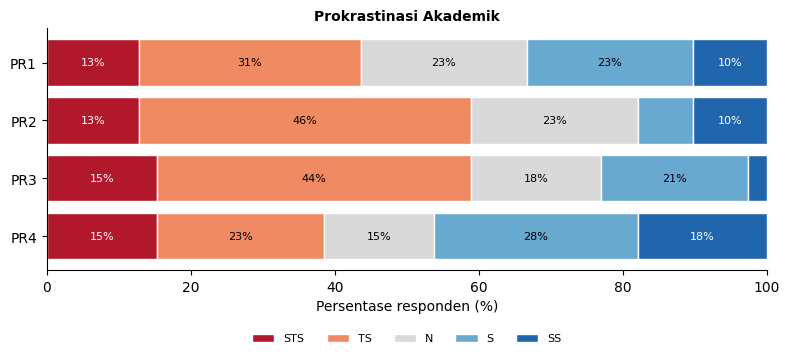

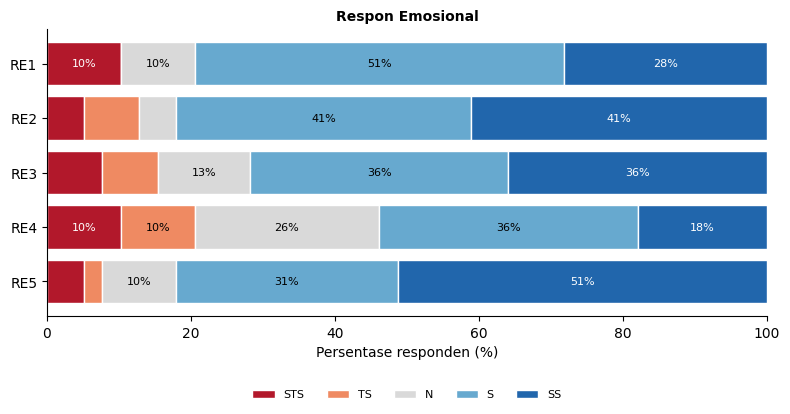

In [11]:
warna = ["#B2182B", "#EF8A62", "#D9D9D9", "#67A9CF", "#2166AC"]    # STS ... SS
label = ["STS", "TS", "N", "S", "SS"]

for nama, daftar in dimensi.items():
    kode, nama_tampil = NAMA_TAMPIL[nama]
    persen = pd.DataFrame({
        f"{kode}{i}": num[k].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0) * 100
        for i, k in enumerate(daftar, 1)
    }).T

    fig, ax = plt.subplots(figsize=(8, 0.55 * len(daftar) + 1.6))
    kiri = np.zeros(len(persen))
    for j, (lab, w) in enumerate(zip(label, warna), 1):
        ax.barh(persen.index, persen[j], left=kiri, color=w, label=lab, edgecolor="white")
        for y, (v, l) in enumerate(zip(persen[j], kiri)):
            if v >= 8:
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if j in (1, 5) else "black")
        kiri += persen[j].values
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (%)")
    ax.set_title(nama_tampil, fontsize=10, fontweight="bold")
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=8)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"grafik_{kode}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Langkah 11 - Menyimpan hasil
File Excel dipakai sebagai dokumentasi/lampiran laporan.

In [12]:
with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)

if DI_COLAB:
    files.download("hasil_uji_validitas_reliabilitas.xlsx")
print("Selesai.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selesai.
